In [59]:
from typing import List, TypedDict
import time
from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS
from langchain_ollama import ChatOllama,OllamaEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate
from langgraph.graph import StateGraph, START, END

In [ ]:
docs = (
    PyPDFLoader("../documents/book1.pdf").load() +
    PyPDFLoader("../documents/book2.pdf").load() +
    PyPDFLoader("../documents/book3.pdf").load()
)

In [61]:
len(docs)

2123

In [62]:
chunks=RecursiveCharacterTextSplitter(chunk_size=900,chunk_overlap=150).split_documents(docs)

In [63]:
len(chunks)

6393

In [64]:
for d in chunks:
   d.page_content = d.page_content.encode("utf-8", "ignore").decode("utf-8", "ignore")

In [65]:
len(chunks)

6393

In [66]:
embedding=OllamaEmbeddings(model="nomic-embed-text")

In [ ]:
#  install faiss-cpu


[notice] A new release of pip is available: 24.2 -> 26.1.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
vector_store=FAISS.from_documents(chunks,embedding)#coverting chunks into vector and then storing them in FAISS database

In [ ]:
#retrive similar documnets
retriver=vector_store.as_retriever(search_type="similarity",search_kwargs={'k':4})

In [ ]:
doc=retriver.invoke("what is supervised machine learning")
for d in doc:
    print(d.page_content[:500])

learning, unsupervised learning, semisupervised learning, and Reinforcement Learn‐
ing.
Supervised learning
In supervised learning, the training data you feed to the algorithm includes the desired
solutions, called labels (Figure 1-5).
Figure 1-5. A labeled training set for supervised learning (e.g., spam classification)
A typical supervised learning task is classification. The spam filter is a good example
of this: it is trained with man y example emails along with their 
class (spam or ham),
a
• Machine Learning is about making machines get better at some task by learning
from data, instead of having to explicitly code rules.
• There are man
y different types of ML systems: supervised or not, batch or online,
instance-based or model-based, and so on.
• In a ML project you gather data in a training set, and you feed the training set to
a learning algorithm. If the algorithm is model-based it tunes some parameters to
fit the model to the training set (i.e., to make good predictions on 

In [ ]:
docs = retriver.invoke("What is a convolutional neural network?")

for doc in docs:
    print(doc.page_content)

Now you know all the building blocks to create a convolutional neural network. Let’s
see how to assemble them.
CNN Architectures
Typical CNN architectures stack a few con volutional la
yers (each one generally fol‐
lowed by a ReLU layer), then a pooling layer, then another few convolutional layers
(+ReLU), then another pooling layer, and so on. The image gets smaller and smaller
as it progresses through the network, but it also typically gets deeper and deeper (i.e.,
with more feature maps) thanks to the convolutional layers (see Figure 13-9). At the
top of the stack, a regular feedforward neural network is added, composed of a few
fully connected layers (+ReLUs), and the final layer outputs the prediction (e.g., a
softmax layer that outputs estimated class probabilities).
Figure 13-9. Typical CNN architecture
A common mistake is to use convolution kernels tha t are too large.
Y
6 A convolution is a mathematical operation that slides one function over another and measures the integral 

In [ ]:
llm=ChatOllama(model="llama3.1:8b")

In [ ]:
class State(TypedDict):
    question:str
    docs:List[Document]
    answer:str


In [ ]:
def retrive(state):#retive documents from the vectorDB
    q=state['question']
    return {"docs":retriver.invoke(q)}

In [ ]:
prompt=ChatPromptTemplate(#ChatPromptTemplate is just a template for creating prompts
    [
("system","from langchain_core.prompts import ChatPromptTemplate"),
("human", "Question: {question}\n\nContext:\n{context}"),
    ]
)

In [ ]:
def generate(state):
    context="\n\n".join(d.page_content for d in state["docs"])
    chain=prompt|llm
    output=chain.invoke({"question":state["question"],"context":context})
    return{"answer":output.content}


In [ ]:
g=StateGraph(State)
g.add_node("retrive",retrive)
g.add_node("generate",generate)

g.add_edge(START,"retrive")
g.add_edge("retrive","generate")
g.add_edge("generate",END)

In [ ]:
app=g.compile()

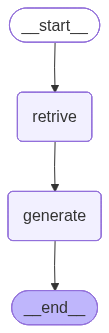

In [ ]:
app

In [ ]:
res=app.invoke({"question":"what is CNN"})

In [ ]:
print(res['docs'][0].page_content)

DeepLearning
IanGoodfellow
YoshuaBengio
AaronCourville


In [ ]:
print(res['docs'][0].page_content)
print('*'*100)
print(res['docs'][1].page_content)
print('*'*100)
print(res['docs'][2].page_content)
print('*'*100)
print(res['docs'][3].page_content)

DeepLearning
IanGoodfellow
YoshuaBengio
AaronCourville
****************************************************************************************************
 D o w n l o a d   f r o m   f i n e l y b o o k   w w w . f i n e l y b o o k . c o m
****************************************************************************************************
 D o w n l o a d   f r o m   f i n e l y b o o k   w w w . f i n e l y b o o k . c o m
****************************************************************************************************
 D o w n l o a d   f r o m   f i n e l y b o o k   w w w . f i n e l y b o o k . c o m
